# COMP4318/5318 Assignment 2: Image Classification

### Group number: ... , SID1: ... , SID2: ... , SID3: ... , SID4: ...

**Owner-specific development notebook: CNN.** The five Canvas sections and other
owners' integration positions are retained. The assessed CNN is built from basic
TensorFlow/Keras layers. The shared seed is **5318** throughout.

This notebook contains actual Canvas-data experiments, an eight-trial validation
search, an independently retrained final CNN, and report-ready figures. Group/SID
details must be completed by the group. Other owners' models and personal
reflections are deliberately left to those owners.

## Setup and dependencies

Use the group's `requirements.yaml` (TensorFlow 2.17.1 and scikit-learn 1.5.2).
Exact versions and hardware for this run are printed below. Run from the repository
root, with the original Canvas data in place. An optional `A2_DATA_DIR` environment
variable can point to the directory containing the four NPY files; no personal
absolute path is hard-coded. `CNN_OUTPUT_DIR` optionally controls exported figures
and CSV files. These exports are conveniences, not inputs required by final training.

The expensive initial-training/search cells are labelled `cnn-initial-training`
and `cnn-search`. In a fresh kernel they can be skipped: run setup, data, model
definitions, the embedded results/plots if desired, and the fixed final-model cells.
Preserve the saved search outputs in the submitted notebook.

In [1]:
from pathlib import Path
from itertools import product
from time import perf_counter
import os
import sys
import json
import random
import platform
import hashlib
import gc

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
import tensorflow as tf
from tensorflow import keras

SEED = 5318
# Configure a modest CPU budget before TensorFlow starts executing operations.
# In an already-initialised merged notebook, the existing thread settings apply.
try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

CNN_OUTPUT_DIR = Path(os.environ.get("CNN_OUTPUT_DIR", "cnn_results"))
CNN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CNN_CLASS_NAMES = [
    "Adipose", "Background", "Debris", "Lymphocytes", "Mucus",
    "Smooth muscle", "Normal colon mucosa", "Cancer-associated stroma",
    "Colorectal adenocarcinoma epithelium",
]
cnn_environment = {
    "seed": SEED, "python": platform.python_version(),
    "numpy": np.__version__, "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__, "tensorflow": tf.__version__,
    "keras": keras.__version__, "platform": platform.platform(),
    "machine": platform.machine(), "logical_cpu_count": os.cpu_count(),
    "tensorflow_devices": [d.name for d in tf.config.list_physical_devices()],
    "intra_op_threads": tf.config.threading.get_intra_op_parallelism_threads(),
    "inter_op_threads": tf.config.threading.get_inter_op_parallelism_threads(),
    "deterministic_ops": True,
}
print(json.dumps(cnn_environment, indent=2))
(CNN_OUTPUT_DIR / "cnn_environment.json").write_text(
    json.dumps(cnn_environment, indent=2), encoding="utf-8"
)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10})

Matplotlib is building the font cache; this may take a moment.


{
  "seed": 5318,
  "python": "3.12.14",
  "numpy": "1.26.4",
  "pandas": "2.2.3",
  "scikit_learn": "1.5.2",
  "tensorflow": "2.17.1",
  "keras": "3.5.0",
  "platform": "macOS-26.3-arm64-arm-64bit",
  "machine": "arm64",
  "logical_cpu_count": 10,
  "tensorflow_devices": [
    "/physical_device:CPU:0"
  ],
  "intra_op_threads": 4,
  "inter_op_threads": 2,
  "deterministic_ops": true
}


## 1. Data loading, exploration, and preprocessing

The four original Canvas files are used without modification. The supplied test
partition is reserved for the frozen final model. The common development split is
`test_size=0.20, stratify=y_train, random_state=5318` **within the original training
partition**, exactly as in the group's template. Class counts and images below
come from development data only. No patient/slide identifiers are available in
these arrays, so patient-level independence cannot be verified.

In [2]:
relative = Path("Canvas Sources") / "Assignment2Data-1" / "Assignment2Data"
data_candidates = [
    base / part
    for base in (Path.cwd(), *Path.cwd().parents)
    for part in (relative, Path("Assignment2Data"))
]
if os.environ.get("A2_DATA_DIR"):
    data_candidates.insert(0, Path(os.environ["A2_DATA_DIR"]).expanduser())
DATA_DIR = next((p for p in data_candidates if (p / "X_train.npy").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Canvas .npy files not found. Run from the repository root or set A2_DATA_DIR."
    )
X_train = np.load(DATA_DIR / "X_train.npy", mmap_mode="r", allow_pickle=False)
y_train = np.load(DATA_DIR / "y_train.npy", allow_pickle=False).reshape(-1).astype(int)
X_test = np.load(DATA_DIR / "X_test.npy", mmap_mode="r", allow_pickle=False)
y_test = np.load(DATA_DIR / "y_test.npy", allow_pickle=False).reshape(-1).astype(int)
assert X_train.ndim == 4 and X_train.shape[1:] == X_test.shape[1:] == (28, 28, 3)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
class_ids = np.unique(y_train)
assert np.array_equal(class_ids, np.arange(9)), "Check the class-to-output mapping."
fit_idx, val_idx = train_test_split(
    np.arange(len(y_train)), test_size=0.20,
    stratify=y_train, random_state=SEED,
)
assert set(fit_idx).isdisjoint(set(val_idx))
assert len(fit_idx) + len(val_idx) == len(y_train)
cnn_train_min, cnn_train_max = float(np.min(X_train)), float(np.max(X_train))
assert 0 <= cnn_train_min <= cnn_train_max <= 255
pixel_divisor = 255.0 if cnn_train_max > 1.0 + 1e-6 else 1.0
X_fit_img = np.asarray(X_train[fit_idx], dtype=np.float32) / pixel_divisor
X_val_img = np.asarray(X_train[val_idx], dtype=np.float32) / pixel_divisor
y_fit, y_val = y_train[fit_idx], y_train[val_idx]
assert np.isfinite(X_fit_img).all() and np.isfinite(X_val_img).all()
assert 0 <= X_fit_img.min() <= X_fit_img.max() <= 1
CNN_INPUT_SHAPE = tuple(X_fit_img.shape[1:])
CNN_NUM_CLASSES = len(class_ids)
cnn_split_fingerprints = {
    "fit_indices_sha256": hashlib.sha256(fit_idx.astype("<i8").tobytes()).hexdigest(),
    "validation_indices_sha256": hashlib.sha256(val_idx.astype("<i8").tobytes()).hexdigest(),
}
print("Canvas training:", X_train.shape, X_train.dtype)
print("Development fit:", X_fit_img.shape, "| validation:", X_val_img.shape)
print("Original held-out test:", X_test.shape, "(not used for model selection)")
print("Training pixel range:", (cnn_train_min, cnn_train_max), "| divisor:", pixel_divisor)
print("Labels:", class_ids.tolist(), "| seed:", SEED)
print(json.dumps(cnn_split_fingerprints, indent=2))
(CNN_OUTPUT_DIR / "cnn_split_fingerprints.json").write_text(
    json.dumps(cnn_split_fingerprints, indent=2), encoding="utf-8"
)

Canvas training: (32000, 28, 28, 3) uint8
Development fit: (25600, 28, 28, 3) | validation: (6400, 28, 28, 3)
Original held-out test: (8000, 28, 28, 3) (not used for model selection)
Training pixel range: (0.0, 255.0) | divisor: 255.0
Labels: [0, 1, 2, 3, 4, 5, 6, 7, 8] | seed: 5318
{
  "fit_indices_sha256": "191d1629061294ebe7e01fe7a79ac57739fced43795161a0c6b821241311c571",
  "validation_indices_sha256": "c07d9573b52ee95cb6bd73390fde64f9c2dccd1c2ab14c244a479b1aa0dd3718"
}


193

,class_id,class_name,original_train,fit,validation
0,0,Adipose,3490,2792,698
1,1,Background,3431,2745,686
2,2,Debris,3505,2804,701
3,3,Lymphocytes,3656,2925,731
4,4,Mucus,2950,2360,590
5,5,Smooth muscle,4290,3432,858
6,6,Normal colon mucosa,2728,2182,546
7,7,Cancer-associated stroma,3253,2602,651
8,8,Colorectal adenocarcinoma epithelium,4697,3758,939


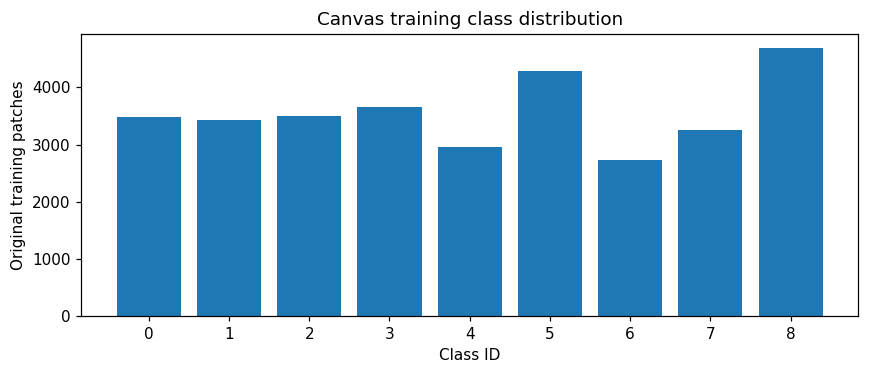

Largest/smallest training-class ratio: 1.722


In [3]:
cnn_class_counts = pd.DataFrame({
    "class_id": class_ids, "class_name": CNN_CLASS_NAMES,
    "original_train": np.bincount(y_train, minlength=CNN_NUM_CLASSES),
    "fit": np.bincount(y_fit, minlength=CNN_NUM_CLASSES),
    "validation": np.bincount(y_val, minlength=CNN_NUM_CLASSES),
})
display(cnn_class_counts)
cnn_class_counts.to_csv(CNN_OUTPUT_DIR / "cnn_development_class_counts.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(cnn_class_counts["class_id"].astype(str), cnn_class_counts["original_train"])
ax.set(xlabel="Class ID", ylabel="Original training patches",
       title="Canvas training class distribution")
fig.tight_layout()
fig.savefig(CNN_OUTPUT_DIR / "cnn_class_distribution.png")
plt.show()
print("Largest/smallest training-class ratio:",
      round(cnn_class_counts.original_train.max() / cnn_class_counts.original_train.min(), 3))

### Examples of preprocessed data

The CNN retains the `(N, 28, 28, 3)` RGB layout. A fixed division by 255 maps the
provided uint8 intensities to [0, 1]; no mean, variance or PCA is estimated from
validation/test images. RGB is retained because colour differences may complement
local tissue texture. The small 28x28 resolution is retained to control runtime.
No augmentation, stain normalisation, class weighting or learned standardisation
is introduced in this controlled comparison; their effects would require separate
validation experiments. Mild class-count differences motivate Macro-F1 selection.

These are visual observations about image appearance, not verified tissue diagnoses.

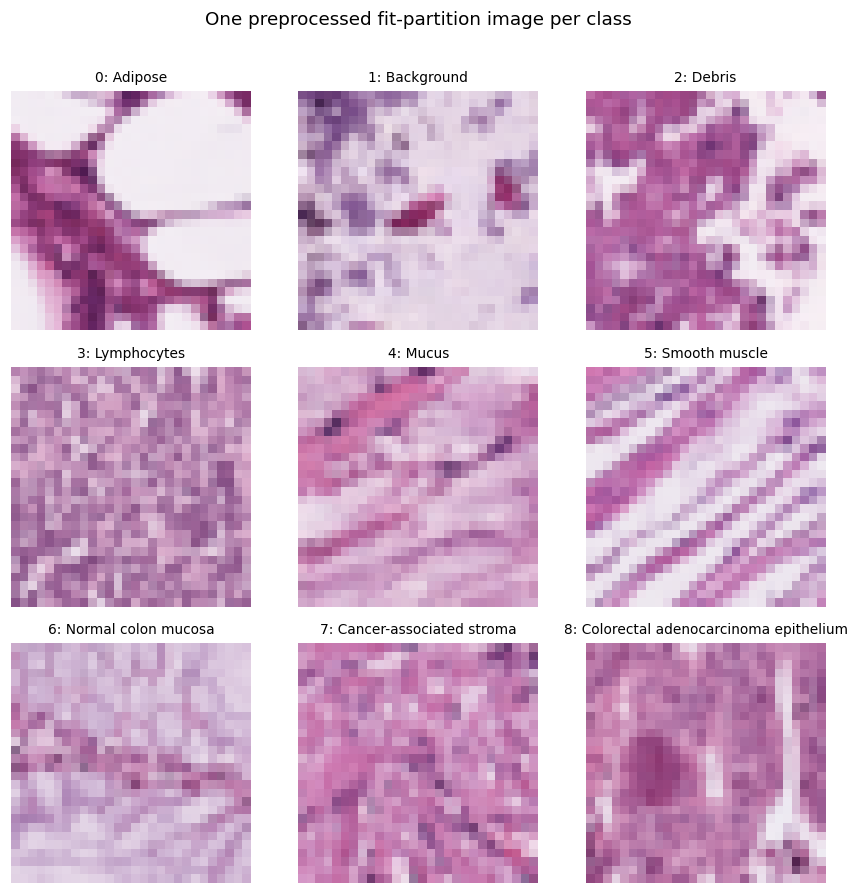

In [4]:
cnn_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for cnn_class, ax in zip(class_ids, axes.ravel()):
    cnn_sample = int(cnn_rng.choice(np.flatnonzero(y_fit == cnn_class)))
    ax.imshow(X_fit_img[cnn_sample])
    ax.set_title(f"{cnn_class}: {CNN_CLASS_NAMES[cnn_class]}", fontsize=9, wrap=True)
    ax.axis("off")
fig.suptitle("One preprocessed fit-partition image per class", y=1.01)
fig.tight_layout()
fig.savefig(CNN_OUTPUT_DIR / "cnn_preprocessed_examples.png", bbox_inches="tight")
plt.show()

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course
To be integrated from the corresponding owner's notebook (Gaussian Naive Bayes).

### Fully connected neural network
To be integrated from the corresponding owner's notebook.

### Convolutional neural network

**Theory and architecture.** Two 3x3 convolutions use local receptive fields and
spatially shared weights to learn image patterns. ReLU supplies nonlinearity.
Each 2x2 max-pooling layer reduces spatial size (28 -> 14 -> 7), reducing later
computation and providing limited local shift tolerance; pooling also discards
detail. Flattening the final feature maps preserves their coarse spatial layout
for a 64-unit dense classifier, followed by dropout and a nine-way softmax.
The dense head contributes substantially to parameter count, so this is not an
assertion that all CNNs are smaller than all MLPs. Inductive bias may help on
local image texture, but relative performance must be established empirically.

`Input(28,28,3) -> Conv(f,3,same)+ReLU -> MaxPool(2) ->`
`Conv(2f,3,same)+ReLU -> MaxPool(2) -> Flatten -> Dense(64,ReLU) ->`
`Dropout(p) -> Dense(9,softmax)`

Adam and sparse categorical cross-entropy are used with integer labels. The
streaming Macro-F1 metric uses a 9x9 confusion matrix, including all nine classes
and zero for zero-denominator classes, matching the group's scikit-learn metric.
Validation Macro-F1 controls early stopping and hyperparameter selection.
All trials reset Python/NumPy/TensorFlow randomness to 5318 and start from new
weights. Deterministic operations improve same-environment reproducibility;
cross-version/device bitwise identity and timing identity are not guaranteed.

The fixed training budget is 12 epochs, batch size 128, and early-stopping patience
3 (restore the best validation-Macro-F1 weights). A two-epoch initial instance
demonstrates functionality before tuning. Its validation performance is descriptive.

In [5]:
CNN_BATCH_SIZE = 128
CNN_MAX_EPOCHS = 12
CNN_PATIENCE = 3

@keras.utils.register_keras_serializable(package="COMP5318")
class CNNMacroF1(keras.metrics.Metric):
    def __init__(self, num_classes=9, name="macro_f1", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = int(num_classes)
        self.matrix = self.add_weight(
            name="confusion", shape=(self.num_classes, self.num_classes),
            initializer="zeros", dtype=tf.float32,
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        actual = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        predicted = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
        weights = None if sample_weight is None else tf.cast(
            tf.reshape(sample_weight, [-1]), tf.float32
        )
        self.matrix.assign_add(tf.math.confusion_matrix(
            actual, predicted, num_classes=self.num_classes,
            weights=weights, dtype=tf.float32,
        ))

    def result(self):
        tp = tf.linalg.diag_part(self.matrix)
        denominator = tf.reduce_sum(self.matrix, axis=0) + tf.reduce_sum(self.matrix, axis=1)
        return tf.reduce_mean(tf.math.divide_no_nan(2.0 * tp, denominator))

    def reset_state(self):
        self.matrix.assign(tf.zeros_like(self.matrix))

    def get_config(self):
        return {**super().get_config(), "num_classes": self.num_classes}


def cnn_measure(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, labels=class_ids, average="macro", zero_division=0
        )),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    }


def cnn_make_dataset(images, targets=None, training=False):
    values = images if targets is None else (images, targets)
    dataset = tf.data.Dataset.from_tensor_slices(values)
    if training:
        dataset = dataset.shuffle(len(images), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.experimental_deterministic = True
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 1
    return dataset.batch(CNN_BATCH_SIZE).with_options(options).prefetch(1)


def cnn_build_model(base_filters, learning_rate, dropout_rate):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input(shape=CNN_INPUT_SHAPE),
        keras.layers.Conv2D(base_filters, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(pool_size=2),
        keras.layers.Conv2D(2 * base_filters, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(pool_size=2),
        keras.layers.Flatten(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(dropout_rate, seed=SEED),
        keras.layers.Dense(CNN_NUM_CLASSES, activation="softmax"),
    ], name="pathmnist_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
                 CNNMacroF1(CNN_NUM_CLASSES)],
        jit_compile=False,
    )
    return model


class CNNEpochLogger(keras.callbacks.Callback):
    # Save per-epoch history and separate training/validation elapsed times.
    def __init__(self, run_name):
        super().__init__()
        self.run_name = run_name
        self.records = []
        self.training_seconds = 0.0
        self.validation_seconds = 0.0

    def on_epoch_begin(self, epoch, logs=None):
        self._epoch_start = perf_counter()
        self._this_validation_seconds = 0.0

    def on_test_begin(self, logs=None):
        self._validation_start = perf_counter()

    def on_test_end(self, logs=None):
        self._this_validation_seconds += perf_counter() - self._validation_start

    def on_epoch_end(self, epoch, logs=None):
        elapsed = perf_counter() - self._epoch_start
        train_elapsed = max(0.0, elapsed - self._this_validation_seconds)
        self.training_seconds += train_elapsed
        self.validation_seconds += self._this_validation_seconds
        record = {
            "run": self.run_name, "epoch": int(epoch + 1),
            **{k: float(v) for k, v in (logs or {}).items()},
            "epoch_seconds": elapsed, "training_seconds": train_elapsed,
            "validation_seconds": self._this_validation_seconds,
        }
        self.records.append(record)
        pd.DataFrame(self.records).to_csv(
            CNN_OUTPUT_DIR / f"{self.run_name}_history.csv", index=False
        )
        if os.environ.get("CNN_PROGRESS_FILE"):
            with Path(os.environ["CNN_PROGRESS_FILE"]).open("a", encoding="utf-8") as stream:
                stream.write(json.dumps(record) + "\n")


def cnn_fit_development(params, run_name, epochs=CNN_MAX_EPOCHS):
    model = cnn_build_model(**params)
    train_data = cnn_make_dataset(X_fit_img, y_fit, training=True)
    validation_data = cnn_make_dataset(X_val_img, y_val)
    timer = CNNEpochLogger(run_name)
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_macro_f1", mode="max", patience=CNN_PATIENCE,
        min_delta=0.0, restore_best_weights=True,
    )
    start = perf_counter()
    history = model.fit(
        train_data, validation_data=validation_data, epochs=epochs,
        callbacks=[timer, early_stop, keras.callbacks.TerminateOnNaN()], verbose=2,
    )
    fit_seconds = perf_counter() - start
    start = perf_counter()
    probabilities = model.predict(cnn_make_dataset(X_val_img), verbose=0)
    validation_seconds = perf_counter() - start
    scores = cnn_measure(y_val, np.argmax(probabilities, axis=1))
    best_epoch = int(np.argmax(history.history["val_macro_f1"]) + 1)
    assert np.isclose(
        scores["macro_f1"], max(history.history["val_macro_f1"]), atol=2e-6
    ), "Restored checkpoint / metric mismatch."
    result = {
        **params, "validation_accuracy": scores["accuracy"],
        "validation_macro_f1": scores["macro_f1"],
        "validation_balanced_accuracy": scores["balanced_accuracy"],
        "fit_seconds": fit_seconds,
        "training_epoch_seconds": timer.training_seconds,
        "in_fit_validation_seconds": timer.validation_seconds,
        "validation_seconds": validation_seconds,
        "epochs_run": len(history.history["loss"]), "best_epoch": best_epoch,
        "parameters": int(model.count_params()),
    }
    return model, history, result


# Verify that the streaming metric agrees with the group's metric, including
# classes absent from a small batch. This check needs no test-set predictions.
cnn_check_true = np.array([0, 0, 1, 1, 2])
cnn_check_pred = np.array([0, 1, 1, 1, 0])
cnn_check_metric = CNNMacroF1(CNN_NUM_CLASSES)
cnn_check_metric.update_state(cnn_check_true, tf.one_hot(cnn_check_pred, CNN_NUM_CLASSES))
assert np.isclose(float(cnn_check_metric.result()), f1_score(
    cnn_check_true, cnn_check_pred, labels=class_ids, average="macro", zero_division=0
), atol=1e-6)
print("Macro-F1 consistency check passed.")
cnn_architecture_preview = cnn_build_model(16, 0.001, 0.3)
cnn_architecture_preview.summary()
del cnn_architecture_preview

Macro-F1 consistency check passed.


Model: "pathmnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,089 (414.41 KB)

 Trainable params: 106,089 (414.41 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
cnn_initial_params = {"base_filters": 16, "learning_rate": 0.001, "dropout_rate": 0.3}
cnn_initial_model, cnn_initial_history, cnn_initial_result = cnn_fit_development(
    cnn_initial_params, "cnn_initial", epochs=2
)
display(pd.DataFrame([cnn_initial_result]).round(5))
del cnn_initial_model
gc.collect()

Epoch 1/2


200/200 - 3s - 14ms/step - accuracy: 0.3200 - loss: 1.7953 - macro_f1: 0.2892 - val_accuracy: 0.3608 - val_loss: 1.5572 - val_macro_f1: 0.3190


Epoch 2/2


200/200 - 2s - 12ms/step - accuracy: 0.4826 - loss: 1.3712 - macro_f1: 0.4560 - val_accuracy: 0.5661 - val_loss: 1.1540 - val_macro_f1: 0.5246


,base_filters,learning_rate,dropout_rate,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,fit_seconds,training_epoch_seconds,in_fit_validation_seconds,validation_seconds,epochs_run,best_epoch,parameters
0,16,0.001,0.3,0.56609,0.52458,0.55056,5.06778,4.61875,0.43798,0.2444,2,2,106089


4

## 3. Hyperparameter tuning

Search uses the shared validation partition, not cross-validation, to make eight
full-data neural-network trials feasible. All 25,600 fit images and 6,400
validation images are used in every trial; no training subset is substituted.
The grid, maximum epochs and selection rule are fixed before looking at test results.

### Algorithm of choice from first six weeks of course
To be integrated from the corresponding owner's notebook.

### Fully connected neural network
To be integrated from the corresponding owner's notebook.

### Convolutional neural network

| Independent hyperparameter | Candidate values | Rationale and prediction |
|---|---|---|
| Base convolution filters f | 8, 16 (second layer fixed at 2f) | Compare modest feature capacity and parameter/runtime cost; more filters may help representation but can overfit. |
| Adam learning rate | 0.001, 0.0003 | Compare faster updates with potentially steadier but slower convergence within the same epoch budget. |
| Dense-head dropout rate | 0.0, 0.3 | Compare no dropout with moderate regularisation; the benefit depends on actual overfitting. |

This is a complete **2 x 2 x 2 grid: three independent hyperparameters and eight
configurations**. The two convolution widths are linked by f and count as one
hyperparameter, not two. Batch size, dense width, kernel size, depth and optimizer
are fixed. Small networks and a bounded grid prioritise explanation and completion.

Trials rank by validation Macro-F1 descending, then fewer parameters, then trial
ID for exact ties. Each uses the best validation-Macro-F1 epoch. Accuracy and
Balanced Accuracy are secondary; test performance never breaks ties.

**Timing:** `fit_seconds` includes the fit call (training, in-fit validation,
callbacks and initial tracing), excluding construction/data preparation.
Training-phase and in-fit validation times are additionally separated by callbacks.
`validation_seconds` measures the separate prediction call after weight restoration.
Per-epoch validation timing includes metric computation. Wall-clock values are
environment-dependent observations, not guaranteed hardware benchmarks.

In [7]:
# EXPENSIVE, ISOLATED SEARCH: final-model cells do not depend on this cell.
cnn_search_records = []
cnn_search_start = perf_counter()
for cnn_trial_id, (cnn_filters, cnn_lr, cnn_dropout) in enumerate(
    product([8, 16], [0.001, 0.0003], [0.0, 0.3]), start=1
):
    cnn_params = {
        "base_filters": cnn_filters,
        "learning_rate": cnn_lr,
        "dropout_rate": cnn_dropout,
    }
    print(f"\nTrial {cnn_trial_id}/8: {cnn_params}", flush=True)
    cnn_trial_model, cnn_trial_history, cnn_trial_record = cnn_fit_development(
        cnn_params, f"cnn_trial_{cnn_trial_id:02d}"
    )
    cnn_trial_record["trial_id"] = cnn_trial_id
    cnn_search_records.append(cnn_trial_record)
    pd.DataFrame(cnn_search_records).to_csv(
        CNN_OUTPUT_DIR / "cnn_search_results.csv", index=False
    )
    print("Restored validation Macro-F1:", round(cnn_trial_record["validation_macro_f1"], 5))
    del cnn_trial_model, cnn_trial_history
    gc.collect()
cnn_search_elapsed = perf_counter() - cnn_search_start
(CNN_OUTPUT_DIR / "cnn_search_timing.json").write_text(
    json.dumps({"search_wall_seconds": cnn_search_elapsed}, indent=2), encoding="utf-8"
)
print(f"Complete search wall time: {cnn_search_elapsed:.2f} seconds")


Trial 1/8: {'base_filters': 8, 'learning_rate': 0.001, 'dropout_rate': 0.0}


Epoch 1/12


200/200 - 2s - 10ms/step - accuracy: 0.3898 - loss: 1.6387 - macro_f1: 0.3592 - val_accuracy: 0.4758 - val_loss: 1.3507 - val_macro_f1: 0.4146


Epoch 2/12


200/200 - 2s - 8ms/step - accuracy: 0.5571 - loss: 1.1839 - macro_f1: 0.5334 - val_accuracy: 0.5864 - val_loss: 1.0998 - val_macro_f1: 0.5353


...

Epoch 11/12


200/200 - 2s - 12ms/step - accuracy: 0.6668 - loss: 0.9203 - macro_f1: 0.6529 - val_accuracy: 0.6973 - val_loss: 0.8511 - val_macro_f1: 0.6823


Epoch 12/12


200/200 - 2s - 12ms/step - accuracy: 0.6762 - loss: 0.9029 - macro_f1: 0.6628 - val_accuracy: 0.7067 - val_loss: 0.8269 - val_macro_f1: 0.6930


Restored validation Macro-F1: 0.69302
Complete search wall time: 219.86 seconds


In [8]:
# The completed run's records are embedded here, so these plots can be recreated
# without rerunning the search or loading an external CSV.
CNN_RECORDED_SEARCH = [{'base_filters': 8,
  'learning_rate': 0.001,
  'dropout_rate': 0.0,
  'validation_accuracy': 0.72390625,
  'validation_macro_f1': 0.7071188152831854,
  'validation_balanced_accuracy': 0.7112265766495496,
  'fit_seconds': 23.08751395798754,
  'training_epoch_seconds': 21.247703959001228,
  'in_fit_validation_seconds': 1.793292165035382,
  'validation_seconds': 0.1904551670304499,
  'epochs_run': 12,
  'best_epoch': 11,
  'parameters': 52217,
  'trial_id': 1},
 {'base_filters': 8,
  'learning_rate': 0.001,
  'dropout_rate': 0.3,
  'validation_accuracy': 0.7196875,
  'validation_macro_f1': 0.7070989868106767,
  'validation_balanced_accuracy': 0.7091763666863569,
  'fit_seconds': 20.072152749984525,
  'training_epoch_seconds': 18.31456629006425,
  'in_fit_validation_seconds': 1.7163062089821324,
  'validation_seconds': 0.185478083032649,
  'epochs_run': 12,
  'best_epoch': 12,
  'parameters': 52217,
  'trial_id': 2},
 {'base_filters': 8,
  'learning_rate': 0.0003,
  'dropout_rate': 0.0,
  'validation_accuracy': 0.6846875,
  'validation_macro_f1': 0.6700556718598493,
  'validation_balanced_accuracy': 0.6744067743000258,
  'fit_seconds': 21.346976416010875,
  'training_epoch_seconds': 19.520689919008873,
  'in_fit_validation_seconds': 1.7759801650536249,
  'validation_seconds': 0.1546262499759905,
  'epochs_run': 12,
  'best_epoch': 12,
  'parameters': 52217,
  'trial_id': 3},
 {'base_filters': 8,
  'learning_rate': 0.0003,
  'dropout_rate': 0.3,
  'validation_accuracy': 0.6784375,
  'validation_macro_f1': 0.6591495899367931,
  'validation_balanced_accuracy': 0.6663843164316794,
  'fit_seconds': 20.29595908394549,
  'training_epoch_seconds': 18.431189125869423,
  'in_fit_validation_seconds': 1.8184757490525951,
  'validation_seconds': 0.3618403750006109,
  'epochs_run': 12,
  'best_epoch': 12,
  'parameters': 52217,
  'trial_id': 4},
 {'base_filters': 16,
  'learning_rate': 0.001,
  'dropout_rate': 0.0,
  'validation_accuracy': 0.72359375,
  'validation_macro_f1': 0.7189614994317537,
  'validation_balanced_accuracy': 0.7175731602553409,
  'fit_seconds': 31.41409462504089,
  'training_epoch_seconds': 29.069617250119336,
  'in_fit_validation_seconds': 2.299534915946424,
  'validation_seconds': 0.2441506249597296,
  'epochs_run': 10,
  'best_epoch': 7,
  'parameters': 106089,
  'trial_id': 5},
 {'base_filters': 16,
  'learning_rate': 0.001,
  'dropout_rate': 0.3,
  'validation_accuracy': 0.75125,
  'validation_macro_f1': 0.7386080336263325,
  'validation_balanced_accuracy': 0.743244847776286,
  'fit_seconds': 34.876283875026274,
  'training_epoch_seconds': 32.26599341788096,
  'in_fit_validation_seconds': 2.5627852910547517,
  'validation_seconds': 0.2476205000421032,
  'epochs_run': 12,
  'best_epoch': 11,
  'parameters': 106089,
  'trial_id': 6},
 {'base_filters': 16,
  'learning_rate': 0.0003,
  'dropout_rate': 0.0,
  'validation_accuracy': 0.72421875,
  'validation_macro_f1': 0.7071348130850215,
  'validation_balanced_accuracy': 0.7103945465519096,
  'fit_seconds': 36.1105295830057,
  'training_epoch_seconds': 33.23610000079498,
  'in_fit_validation_seconds': 2.7460907511995174,
  'validation_seconds': 0.2172301660175435,
  'epochs_run': 12,
  'best_epoch': 12,
  'parameters': 106089,
  'trial_id': 7},
 {'base_filters': 16,
  'learning_rate': 0.0003,
  'dropout_rate': 0.3,
  'validation_accuracy': 0.70671875,
  'validation_macro_f1': 0.6930185769172292,
  'validation_balanced_accuracy': 0.6969347446915147,
  'fit_seconds': 28.855340124981012,
  'training_epoch_seconds': 26.558024003054015,
  'in_fit_validation_seconds': 2.2554484980064444,
  'validation_seconds': 0.2047152500017546,
  'epochs_run': 12,
  'best_epoch': 12,
  'parameters': 106089,
  'trial_id': 8}]
cnn_search_results = pd.DataFrame(
    cnn_search_records if "cnn_search_records" in globals() else CNN_RECORDED_SEARCH
)
cnn_ranked_results = cnn_search_results.sort_values(
    ["validation_macro_f1", "parameters", "trial_id"],
    ascending=[False, True, True], kind="stable",
).reset_index(drop=True)
display(cnn_ranked_results.round(5))

,base_filters,learning_rate,dropout_rate,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,fit_seconds,training_epoch_seconds,in_fit_validation_seconds,validation_seconds,epochs_run,best_epoch,parameters,trial_id
0,16,0.0010,0.3,0.75125,0.73861,0.74324,34.87628,32.26599,2.56279,0.24762,12,11,106089,6
1,16,0.0010,0.0,0.72359,0.71896,0.71757,31.41409,29.06962,2.29953,0.24415,10,7,106089,5
2,16,0.0003,0.0,0.72422,0.70713,0.71039,36.11053,33.23610,2.74609,0.21723,12,12,106089,7
3,8,0.0010,0.0,0.72391,0.70712,0.71123,23.08751,21.24770,1.79329,0.19046,12,11,52217,1
4,8,0.0010,0.3,0.71969,0.70710,0.70918,20.07215,18.31457,1.71631,0.18548,12,12,52217,2
5,16,0.0003,0.3,0.70672,0.69302,0.69693,28.85534,26.55802,2.25545,0.20472,12,12,106089,8
6,8,0.0003,0.0,0.68469,0.67006,0.67441,21.34698,19.52069,1.77598,0.15463,12,12,52217,3
7,8,0.0003,0.3,0.67844,0.65915,0.66638,20.29596,18.43119,1.81848,0.36184,12,12,52217,4


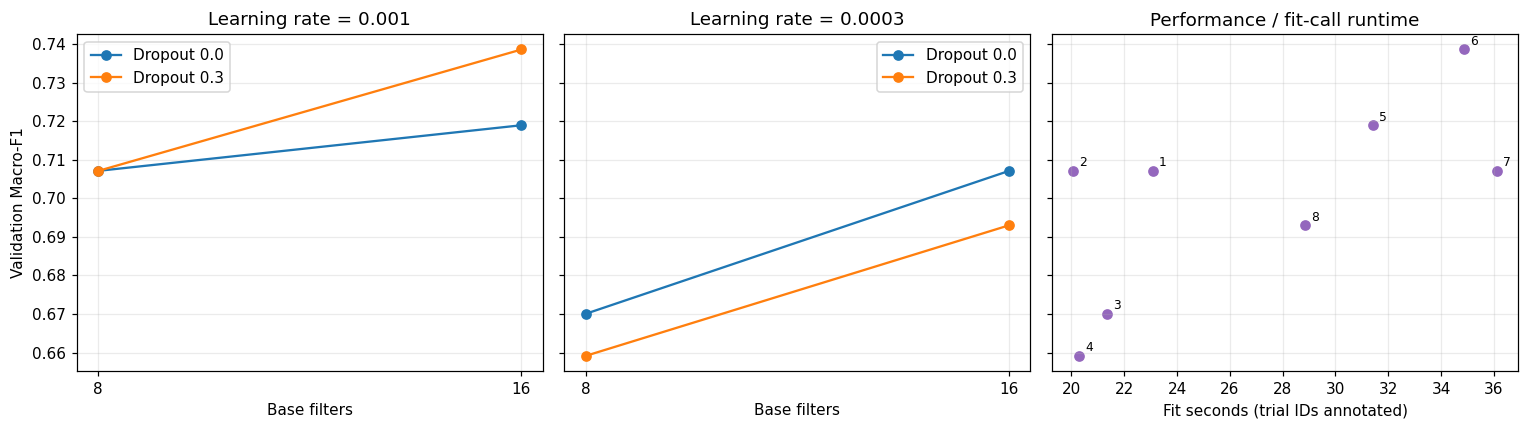

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, cnn_lr in zip(axes[:2], [0.001, 0.0003]):
    for cnn_dropout in [0.0, 0.3]:
        subset = cnn_search_results[
            (cnn_search_results.learning_rate == cnn_lr) &
            (cnn_search_results.dropout_rate == cnn_dropout)
        ].sort_values("base_filters")
        ax.plot(subset.base_filters, subset.validation_macro_f1,
                marker="o", label=f"Dropout {cnn_dropout}")
    ax.set(title=f"Learning rate = {cnn_lr}", xlabel="Base filters", xticks=[8, 16])
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Validation Macro-F1")
axes[2].scatter(cnn_search_results.fit_seconds,
                cnn_search_results.validation_macro_f1, color="tab:purple")
for row in cnn_search_results.itertuples():
    axes[2].annotate(str(row.trial_id), (row.fit_seconds, row.validation_macro_f1),
                     xytext=(4, 3), textcoords="offset points", fontsize=8)
axes[2].set(title="Performance / fit-call runtime", xlabel="Fit seconds (trial IDs annotated)")
axes[2].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(CNN_OUTPUT_DIR / "cnn_hyperparameter_trends.png")
plt.show()

### Actual search results and interpretation

The selected configuration is **f=16, learning rate=0.001,
dropout=0.3**, with validation Macro-F1 **0.7386**,
Accuracy **0.7512**, and Balanced Accuracy
**0.7432**. Its best checkpoint is epoch
**11** (out of 12 executed epochs), with
**106,089 parameters**. The complete eight-trial search took
**219.86 seconds** in the recorded environment.

Grid-averaged validation Macro-F1 (descriptive averages over the other settings):

- Base filters: 8: 0.6859, 16: 0.7144.
- Learning rate: 0.0003: 0.6823, 0.001: 0.7179.
- Dropout: 0: 0.7008, 0.3: 0.6995.

These averages describe this bounded search, not population-level significance.
Use the matched-condition lines in the figure to inspect interactions: a capacity
or regularisation change need not help at both learning rates. A lower learning
rate may need more epochs than the fixed budget permits; a higher-capacity model
may improve representation while increasing computation. Dropout can reduce
overfitting but can also slow fitting or be unnecessary for a small architecture.
The actual ordering above, rather than an assumption that bigger/regularised is
always better, determines selection. Per-epoch curves show how the selected
checkpoint relates to later development behaviour.

Trial wall times also depend on actual epochs, graph tracing and callback costs;
they should not be attributed solely to one parameter. Each trial is one seeded
run on one development split, so small differences need repeated-seed experiments.
No test score participated in this selection.


## 4. Final models

The configuration and epoch budget below are frozen from validation results,
before test prediction. The final CNN is created from fresh weights and trains
on **all 32,000 original training images** for the selected best epoch count.
No validation or test-based early stopping is used in this full-data retrain.
Thus final training uses the same original sample pool as the group's GaussianNB
and fixed baselines. A fixed epoch count transfers the validation choice to the
larger sample pool; it is a practical protocol, not proof of an optimal full-data
training duration. All test diagnostics reuse one cached prediction array.

### Algorithm of choice from first six weeks of course
To be integrated from the corresponding owner's notebook.

### Fully connected neural network
To be integrated from the corresponding owner's notebook.

### Convolutional neural network

In [10]:
# Actual validation-selected choices; no search object is needed.
CNN_BEST_PARAMS = {'base_filters': 16, 'learning_rate': 0.001, 'dropout_rate': 0.3}
CNN_FINAL_EPOCHS = 11
CNN_SELECTED_VALIDATION = {'trial_id': 6, 'macro_f1': 0.7386080336263325, 'accuracy': 0.75125, 'balanced_accuracy': 0.743244847776286}
print('Frozen CNN configuration:', CNN_BEST_PARAMS)
print('Fixed full-data training epochs:', CNN_FINAL_EPOCHS)
print('Recorded selection result:', CNN_SELECTED_VALIDATION)

Frozen CNN configuration: {'base_filters': 16, 'learning_rate': 0.001, 'dropout_rate': 0.3}
Fixed full-data training epochs: 11
Recorded selection result: {'trial_id': 6, 'macro_f1': 0.7386080336263325, 'accuracy': 0.75125, 'balanced_accuracy': 0.743244847776286}


In [11]:
# No search object, saved checkpoint or external log is required for this cell.
cnn_full_train_img = np.asarray(X_train, dtype=np.float32) / pixel_divisor
cnn_final_train_data = cnn_make_dataset(cnn_full_train_img, y_train, training=True)
cnn_final_model = cnn_build_model(**CNN_BEST_PARAMS)
cnn_final_logger = CNNEpochLogger("cnn_final")
cnn_final_start = perf_counter()
cnn_final_history = cnn_final_model.fit(
    cnn_final_train_data, epochs=CNN_FINAL_EPOCHS,
    callbacks=[cnn_final_logger, keras.callbacks.TerminateOnNaN()], verbose=2,
)
cnn_final_fit_seconds = perf_counter() - cnn_final_start
print(f"Final training: {len(y_train)} images, {CNN_FINAL_EPOCHS} epochs, "
      f"{cnn_final_fit_seconds:.3f} seconds, {cnn_final_model.count_params():,} parameters")

Epoch 1/11


250/250 - 3s - 12ms/step - accuracy: 0.3008 - loss: 1.8287 - macro_f1: 0.2552


Epoch 2/11


250/250 - 3s - 11ms/step - accuracy: 0.4617 - loss: 1.4035 - macro_f1: 0.4270


Epoch 3/11


...

Epoch 10/11


250/250 - 3s - 11ms/step - accuracy: 0.6407 - loss: 0.9621 - macro_f1: 0.6179


Epoch 11/11


250/250 - 3s - 11ms/step - accuracy: 0.6518 - loss: 0.9431 - macro_f1: 0.6302


Final training: 32000 images, 11 epochs, 30.181 seconds, 106,089 parameters


In [12]:
# First and only test prediction in this run; all subsequent diagnostics reuse it.
cnn_test_img = np.asarray(X_test, dtype=np.float32) / pixel_divisor
cnn_test_data = cnn_make_dataset(cnn_test_img)
cnn_prediction_start = perf_counter()
cnn_test_probabilities = cnn_final_model.predict(cnn_test_data, verbose=0)
cnn_test_predict_seconds = perf_counter() - cnn_prediction_start
assert cnn_test_probabilities.shape == (len(y_test), CNN_NUM_CLASSES)
assert np.isfinite(cnn_test_probabilities).all()
assert np.allclose(cnn_test_probabilities.sum(axis=1), 1.0, atol=1e-5)
cnn_test_predictions = np.argmax(cnn_test_probabilities, axis=1)
cnn_test_scores = cnn_measure(y_test, cnn_test_predictions)
cnn_final_result = {
    "model": "CNN", "best_hyperparameters": json.dumps(CNN_BEST_PARAMS, sort_keys=True),
    "validation_macro_f1": CNN_SELECTED_VALIDATION["macro_f1"],
    "validation_accuracy": CNN_SELECTED_VALIDATION["accuracy"],
    "test_accuracy": cnn_test_scores["accuracy"],
    "test_macro_f1": cnn_test_scores["macro_f1"],
    "test_balanced_accuracy": cnn_test_scores["balanced_accuracy"],
    "fit_seconds": cnn_final_fit_seconds, "prediction_seconds": cnn_test_predict_seconds,
    "parameters": int(cnn_final_model.count_params()), "epochs": CNN_FINAL_EPOCHS,
    "search_fit_samples": len(y_fit), "validation_samples": len(y_val),
    "train_samples": len(y_train), "test_samples": len(y_test), "seed": SEED,
}
cnn_final_results = pd.DataFrame([cnn_final_result])
display(cnn_final_results.T.rename(columns={0: "value"}))
print(classification_report(
    y_test, cnn_test_predictions, labels=class_ids,
    target_names=CNN_CLASS_NAMES, digits=4, zero_division=0,
))
cnn_classification_report = pd.DataFrame(classification_report(
    y_test, cnn_test_predictions, labels=class_ids, target_names=CNN_CLASS_NAMES,
    output_dict=True, zero_division=0,
)).T
cnn_final_results.to_csv(CNN_OUTPUT_DIR / "cnn_final_results.csv", index=False)
cnn_classification_report.to_csv(CNN_OUTPUT_DIR / "cnn_classification_report.csv")
np.save(CNN_OUTPUT_DIR / "cnn_test_predictions.npy", cnn_test_predictions)
np.save(CNN_OUTPUT_DIR / "cnn_test_probabilities.npy", cnn_test_probabilities)
(CNN_OUTPUT_DIR / "cnn_final_summary.json").write_text(json.dumps({
    **cnn_final_result, "best_hyperparameters": CNN_BEST_PARAMS,
    "environment": cnn_environment, "split_fingerprints": cnn_split_fingerprints,
}, indent=2), encoding="utf-8")
# Optional convenience checkpoint. Final training never requires this file.
cnn_final_model.save(CNN_OUTPUT_DIR / "cnn_final_model.keras")

,value
model,CNN
best_hyperparameters,"{""base_filters"": 16, ""dropout_rate"": 0.3, ""lea..."
validation_macro_f1,0.738608
validation_accuracy,0.75125
test_accuracy,0.720375
test_macro_f1,0.69786
test_balanced_accuracy,0.705091
fit_seconds,30.181307
prediction_seconds,0.248718
parameters,106089


                                      precision    recall  f1-score   support

                             Adipose     0.8452    0.9759    0.9059       873
                          Background     0.9718    0.9231    0.9468       858
                              Debris     0.8406    0.2645    0.4024       877
                         Lymphocytes     0.8924    0.9530    0.9217       914
                               Mucus     0.6932    0.6866    0.6898       737
                       Smooth muscle     0.6459    0.7640    0.7000      1072
                 Normal colon mucosa     0.6326    0.4897    0.5521       682
            Cancer-associated stroma     0.4613    0.4330    0.4467       813
Colorectal adenocarcinoma epithelium     0.6143    0.8560    0.7153      1174

                            accuracy                         0.7204      8000
                           macro avg     0.7330    0.7051    0.6979      8000
                        weighted avg     0.7319    0.7204    0

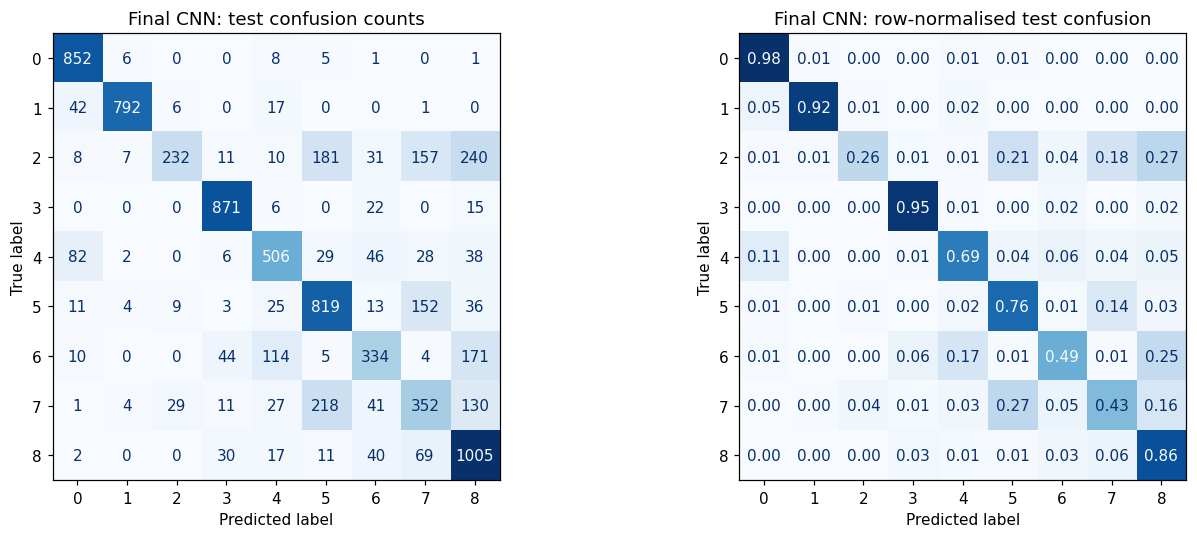

,class_id,class_name,precision,recall,f1_score,support
0,0,Adipose,0.8452,0.9759,0.9059,873
1,1,Background,0.9718,0.9231,0.9468,858
2,2,Debris,0.8406,0.2645,0.4024,877
3,3,Lymphocytes,0.8924,0.9530,0.9217,914
4,4,Mucus,0.6932,0.6866,0.6898,737
5,5,Smooth muscle,0.6459,0.7640,0.7000,1072
6,6,Normal colon mucosa,0.6326,0.4897,0.5521,682
7,7,Cancer-associated stroma,0.4613,0.4330,0.4467,813
8,8,Colorectal adenocarcinoma epithelium,0.6143,0.8560,0.7153,1174


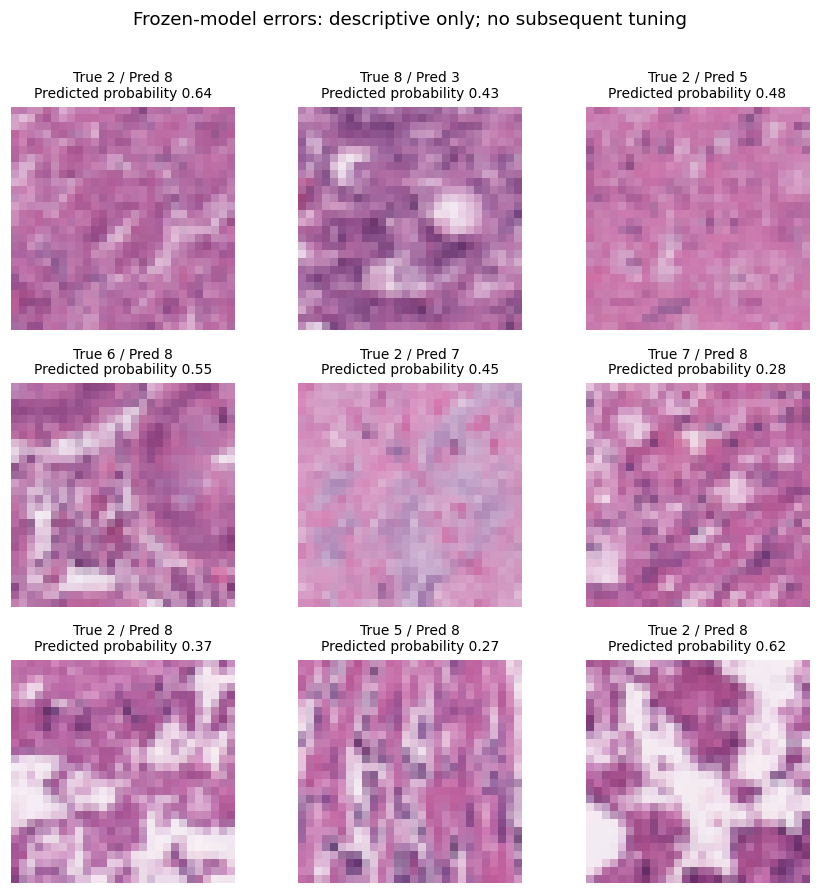

Largest directed test confusions (count, true ID, predicted ID): [(240, 2, 8), (218, 7, 5), (181, 2, 5), (171, 6, 8), (157, 2, 7)]


In [13]:
cnn_cm = confusion_matrix(y_test, cnn_test_predictions, labels=class_ids)
np.savetxt(CNN_OUTPUT_DIR / "cnn_confusion_matrix.csv", cnn_cm, delimiter=",", fmt="%d")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cnn_cm, display_labels=class_ids).plot(
    ax=axes[0], colorbar=False, cmap="Blues", values_format="d"
)
cnn_cm_normalised = cnn_cm / cnn_cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(cnn_cm_normalised, display_labels=class_ids).plot(
    ax=axes[1], colorbar=False, cmap="Blues", values_format=".2f"
)
axes[0].set_title("Final CNN: test confusion counts")
axes[1].set_title("Final CNN: row-normalised test confusion")
fig.tight_layout()
fig.savefig(CNN_OUTPUT_DIR / "cnn_confusion_matrices.png")
plt.show()

cnn_per_class = pd.DataFrame({
    "class_id": class_ids, "class_name": CNN_CLASS_NAMES,
    "precision": [cnn_classification_report.loc[n, "precision"] for n in CNN_CLASS_NAMES],
    "recall": [cnn_classification_report.loc[n, "recall"] for n in CNN_CLASS_NAMES],
    "f1_score": [cnn_classification_report.loc[n, "f1-score"] for n in CNN_CLASS_NAMES],
    "support": [int(cnn_classification_report.loc[n, "support"]) for n in CNN_CLASS_NAMES],
})
display(cnn_per_class.round(4))
cnn_per_class.to_csv(CNN_OUTPUT_DIR / "cnn_per_class_results.csv", index=False)

# Error examples are post-evaluation diagnostics, never inputs to further tuning.
cnn_wrong_indices = np.flatnonzero(cnn_test_predictions != y_test)
cnn_chosen_errors = np.random.default_rng(SEED).choice(
    cnn_wrong_indices, size=min(9, len(cnn_wrong_indices)), replace=False
)
if len(cnn_chosen_errors):
    fig, axes = plt.subplots(3, 3, figsize=(8, 8))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, index in zip(axes.ravel(), cnn_chosen_errors):
        ax.imshow(cnn_test_img[index])
        ax.set_title(
            f"True {y_test[index]} / Pred {cnn_test_predictions[index]}\n"
            f"Predicted probability {cnn_test_probabilities[index].max():.2f}", fontsize=9
        )
    fig.suptitle("Frozen-model errors: descriptive only; no subsequent tuning", y=1.01)
    fig.tight_layout()
    fig.savefig(CNN_OUTPUT_DIR / "cnn_error_examples.png", bbox_inches="tight")
    plt.show()

cnn_off_diagonal = cnn_cm.copy()
np.fill_diagonal(cnn_off_diagonal, 0)
cnn_error_pairs = sorted(
    [(int(cnn_off_diagonal[i, j]), int(i), int(j))
     for i in class_ids for j in class_ids if i != j], reverse=True
)[:5]
print("Largest directed test confusions (count, true ID, predicted ID):", cnn_error_pairs)

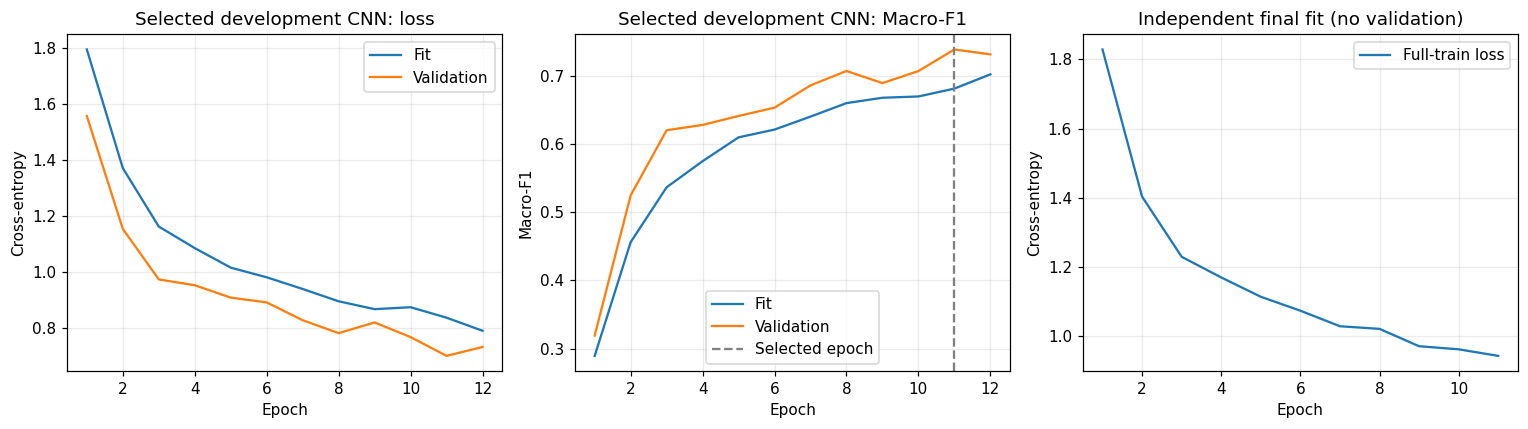

In [14]:
# The selected development history is embedded for search-skipping portability.
CNN_RECORDED_BEST_HISTORY = [{'run': 'cnn_trial_06',
  'epoch': 1,
  'accuracy': 0.3200390636920929,
  'loss': 1.7952613830566406,
  'macro_f1': 0.2892268896102905,
  'val_accuracy': 0.3607812523841858,
  'val_loss': 1.557167410850525,
  'val_macro_f1': 0.3189676403999328,
  'epoch_seconds': 2.766680374974385,
  'training_seconds': 2.511575374926906,
  'validation_seconds': 0.2551050000474788},
 {'run': 'cnn_trial_06',
  'epoch': 2,
  'accuracy': 0.4825781285762787,
  'loss': 1.371219038963318,
  'macro_f1': 0.4559575319290161,
  'val_accuracy': 0.5660937428474426,
  'val_loss': 1.1539781093597412,
  'val_macro_f1': 0.5245829224586487,
  'epoch_seconds': 2.455964208988007,
  'training_seconds': 2.255021959019359,
  'validation_seconds': 0.2009422499686479},
 {'run': 'cnn_trial_06',
  'epoch': 3,
  'accuracy': 0.5624609589576721,
  'loss': 1.1623963117599487,
  'macro_f1': 0.5364950895309448,
  'val_accuracy': 0.6493750214576721,
  'val_loss': 0.9734728932380676,
  'val_macro_f1': 0.6201698780059814,
  'epoch_seconds': 2.835984457982704,
  'training_seconds': 2.619155624997802,
  'validation_seconds': 0.2168288329849019},
 {'run': 'cnn_trial_06',
  'epoch': 4,
  'accuracy': 0.5972265601158142,
  'loss': 1.0853347778320312,
  'macro_f1': 0.5747848749160767,
  'val_accuracy': 0.6532812714576721,
  'val_loss': 0.9526664614677428,
  'val_macro_f1': 0.6279528141021729,
  'epoch_seconds': 3.122885917022358,
  'training_seconds': 2.7574141250224784,
  'validation_seconds': 0.3654717919998802},
 {'run': 'cnn_trial_06',
  'epoch': 5,
  'accuracy': 0.6303515434265137,
  'loss': 1.0155609846115112,
  'macro_f1': 0.6097464561462402,
  'val_accuracy': 0.671875,
  'val_loss': 0.9083418250083924,
  'val_macro_f1': 0.6410682201385498,
  'epoch_seconds': 6.020319208037108,
  'training_seconds': 5.802434917073697,
  'validation_seconds': 0.2178842909634113},
 {'run': 'cnn_trial_06',
  'epoch': 6,
  'accuracy': 0.6424999833106995,
  'loss': 0.9810275435447692,
  'macro_f1': 0.6211313605308533,
  'val_accuracy': 0.668749988079071,
  'val_loss': 0.8913350701332092,
  'val_macro_f1': 0.6532936096191406,
  'epoch_seconds': 2.7159460419788957,
  'training_seconds': 2.52850741695147,
  'validation_seconds': 0.1874386250274256},
 {'run': 'cnn_trial_06',
  'epoch': 7,
  'accuracy': 0.6589453220367432,
  'loss': 0.9392419457435608,
  'macro_f1': 0.6401779651641846,
  'val_accuracy': 0.7010937333106995,
  'val_loss': 0.8276249170303345,
  'val_macro_f1': 0.6859519481658936,
  'epoch_seconds': 2.4772590000065975,
  'training_seconds': 2.2995623750030063,
  'validation_seconds': 0.1776966250035911},
 {'run': 'cnn_trial_06',
  'epoch': 8,
  'accuracy': 0.6771484613418579,
  'loss': 0.8952361941337585,
  'macro_f1': 0.6599345803260803,
  'val_accuracy': 0.7206249833106995,
  'val_loss': 0.7814446091651917,
  'val_macro_f1': 0.7070592641830444,
  'epoch_seconds': 2.443788875010796,
  'training_seconds': 2.2596617500530556,
  'validation_seconds': 0.1841271249577403},
 {'run': 'cnn_trial_06',
  'epoch': 9,
  'accuracy': 0.683789074420929,
  'loss': 0.8671367764472961,
  'macro_f1': 0.6678196787834167,
  'val_accuracy': 0.699999988079071,
  'val_loss': 0.8196848034858704,
  'val_macro_f1': 0.6893212795257568,
  'epoch_seconds': 2.495565582998097,
  'training_seconds': 2.310696166998241,
  'validation_seconds': 0.1848694159998558},
 {'run': 'cnn_trial_06',
  'epoch': 10,
  'accuracy': 0.6849609613418579,
  'loss': 0.8740715980529785,
  'macro_f1': 0.6696906685829163,
  'val_accuracy': 0.7256249785423279,
  'val_loss': 0.7673020958900452,
  'val_macro_f1': 0.7069990634918213,
  'epoch_seconds': 2.493701624975074,
  'training_seconds': 2.3009472499252297,
  'validation_seconds': 0.1927543750498443},
 {'run': 'cnn_trial_06',
  'epoch': 11,
  'accuracy': 0.696093738079071,
  'loss': 0.8366530537605286,
  'macro_f1': 0.6812673211097717,
  'val_accuracy': 0.7512500286102295,
  'val_loss': 0.7001819610595703,
  'val_macro_f1': 0.7386080622673035,
  'epoch_seconds': 2.511206624971237,
  'training_seconds': 2.319451457937248,
  'validation_seconds': 0.1917551670339889},
 {'run': 'cnn_trial_06',
  'epoch': 12,
  'accuracy': 0.7159765362739563,
  'loss': 0.789919912815094,
  'macro_f1': 0.7021493911743164,
  'val_accuracy': 0.7378125190734863,
  'val_loss': 0.731890857219696,
  'val_macro_f1': 0.7314484715461731,
  'epoch_seconds': 2.4894767919904552,
  'training_seconds': 2.30156499997247,
  'validation_seconds': 0.1879117920179851}]
cnn_best_history_frame = pd.DataFrame(CNN_RECORDED_BEST_HISTORY)
cnn_final_history_frame = pd.DataFrame(cnn_final_logger.records)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(cnn_best_history_frame.epoch, cnn_best_history_frame.loss, label="Fit")
axes[0].plot(cnn_best_history_frame.epoch, cnn_best_history_frame.val_loss, label="Validation")
axes[0].set(title="Selected development CNN: loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].plot(cnn_best_history_frame.epoch, cnn_best_history_frame.macro_f1, label="Fit")
axes[1].plot(cnn_best_history_frame.epoch, cnn_best_history_frame.val_macro_f1, label="Validation")
axes[1].axvline(CNN_FINAL_EPOCHS, color="grey", linestyle="--", label="Selected epoch")
axes[1].set(title="Selected development CNN: Macro-F1", xlabel="Epoch", ylabel="Macro-F1")
axes[2].plot(cnn_final_history_frame.epoch, cnn_final_history_frame.loss, label="Full-train loss")
axes[2].set(title="Independent final fit (no validation)", xlabel="Epoch", ylabel="Cross-entropy")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(CNN_OUTPUT_DIR / "cnn_learning_curves.png")
plt.show()

### Actual final results and discussion

The independently initialised CNN trained on **32,000 images**
for **11 fixed epochs**. On the original **8,000
held-out test images**, it obtained **Accuracy 0.7204**,
**Macro-F1 0.6979**, and **Balanced Accuracy
0.7051**. Final fit-call time was
**30.18 s** and test prediction time was
**0.25 s**, excluding loading, model construction and
plotting. The model has **106,089 trainable parameters**.

The highest test recall was for **Adipose (0.9759)**;
the lowest was for **Debris (0.2645)**. The largest directed
confusions (count, true class, predicted class) were **[(240, 2, 8), (218, 7, 5), (181, 2, 5)]**. Row-normalised
confusion plots account for class support differences. Sampled mistakes are
descriptive and do not establish biological causes or justify subsequent tuning.

Development selection Macro-F1 was 0.7386. Its difference
from final test Macro-F1 is not a clean overfitting estimate: the final model was
retrained from scratch on 32,000 rather than 25,600 images and evaluated on a
different partition. The development fit/validation curves, rather than that
difference alone, are the appropriate evidence for training behaviour.

Local receptive fields and weight sharing motivate this CNN for spatial image
patterns, but comparison with the MLP/traditional method must use their actual
final results, matching data and timing conditions. This notebook does not invent
other owners' measurements or claim controlled cross-machine speed advantages.


### Integration and limitations

- Keep the group's common loading/split cells **once**. Verify their fit/validation
  index fingerprints match this notebook and that `X_fit_img`, `X_val_img`,
  `y_fit`, `y_val`, `class_ids`, `pixel_divisor`, `X_train`, `y_train`, `X_test`,
  and `y_test` remain available. CNN-specific functions, classes and result names
  are prefixed to reduce collisions with other owners' models.
- Retain CNN setup/imports, definitions, recorded/frozen choices and final cells
  when integrating. Copy search cells **with their saved outputs**. Never require
  another owner's `model`, `history`, search object or local checkpoint.
- Macro-F1 is the validation selection criterion. Final test metrics use all nine
  classes in their original label order; no test results guide further changes.
- One split/seed and a small grid limit certainty. No repeated-seed confidence
  interval is claimed. Raw pixel preprocessing does not address possible stain
  variation, and no patient metadata supports a patient-level independence check.
- The full-data final retrain and development checkpoints have different sample
  counts. Compare final models using the reported training pool, hardware and
  timing boundaries. Other owners' models are not rerun or modified here.
- Each student must write their **own** reflection. This notebook does not invent
  personal learning experiences, group identifiers or member contributions.

**Concrete future work:** repeat the frozen shortlist with multiple predeclared
seeds to estimate variability; evaluate a separately controlled training-only
augmentation experiment; if confusion persists, inspect development-set errors
and test a predeclared architectural change on validation data. These remain
proposals, not experiments already performed.

## 5. AI Acknowledgement

ChatGPT/Codex (OpenAI) assisted with interpreting the assignment and group template,
designing and implementing this CNN module, dependency setup, local experiment
execution, debugging, visualisation, and drafting result interpretations/integration
notes. The fixed seed is 5318. Numerical claims in this notebook are generated by
the recorded local executions on the supplied Canvas arrays. The group must review
the code and explanations, add actual group/SID information, write individual
reflections, and ensure the report's AI acknowledgement reflects all actual usage.

### References

1. Canvas assignment specification and template, supplied with this workspace.
2. Group workspace README: shared seed, data split and Macro-F1 evaluation protocol.
3. [Keras Conv2D API](https://keras.io/api/layers/convolution_layers/convolution2d/).
4. [Keras EarlyStopping API](https://keras.io/api/callbacks/early_stopping/).
5. [TensorFlow random-seed utility](https://www.tensorflow.org/api_docs/python/tf/keras/utils/set_random_seed).
6. [TensorFlow operation determinism](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism).
7. [scikit-learn F1 score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html).

Class names follow the group's existing baseline mapping. The data source and
MedMNIST attribution should also be included in the combined report's references.